# Gradient Boosting classifier: financial hit or bust
Predict **`success`** from the engineered inputs in `../../data/model_data_success.csv`.

- **1 — Hit:** reported revenue is at least 2.5 times budget.
- **0 — Bust:** reported revenue is below that benchmark.

These are project labels, not audited profit/loss. Builds shallow trees sequentially to improve classification errors. All classifiers use the same chronological split, validation folds, and feature groups. Initial and training-validation-selected settings are compared below.

Run all cells from `Modeling_scripts/success_models/` using `ds6001`. This notebook trains in memory, displays results, and does not write datasets or model files.

Section 4 validates/tunes settings without using the later test data to choose them.

The current model table includes directors' earlier-year rating history, its supporting film count, and a no-history flag. These use retrospective ratings on strictly earlier films; the target movie's rating is still excluded from predictors.

`log_budget` is the base-10 log of reported production budget. Unknown budgets remain missing in rating data and are median-imputed using training rows only. Current revenue and outcomes are excluded from predictors.

## Tuning controls — edit here first

1. Edit the controls in the next cell.
2. **Save the notebook and Run All** so every result uses the same settings.
3. Review the validation table, then the later-test table. Do not repeatedly tune against test scores.

| What you want to change | Control |
|---|---|
| Original model or a setting not searched | `MODEL_SETTINGS` |
| Trial values for model settings | `PARAM_GRID` (lists); these override `MODEL_SETTINGS` during search |
| Which score selects settings | `TUNING_METRIC` |
| Feature groups to compare | `FEATURE_GROUPS_TO_COMPARE` |
| Required mean validation hit precision | `MIN_VALIDATION_PRECISION` (currently 0.70) |
| Final hit thresholds to test | `THRESHOLDS` |
| Date boundary and number of validation folds | `CUTOFF_DATE`, `N_VALIDATION_SPLITS`; keep consistent across models |

`n_estimators` controls tree count and `max_depth` tree complexity; `learning_rate` is fixed in `MODEL_SETTINGS` unless added to the grid.

**Example:** Try the tree-count/depth lists in `PARAM_GRID`; edit `learning_rate` in `MODEL_SETTINGS` if it is not searched. Keep parameter key names unchanged when editing trial values.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_success.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {'n_estimators': 150,
 'learning_rate': 0.05,
 'max_depth': 3,
 'min_samples_leaf': 10,
 'random_state': 42}

# CHANGE THESE LISTS to try model settings. More values mean a longer run.
# Empty for OLS: use Ridge for regularization, or change feature groups below.
PARAM_GRID = {'classifier__n_estimators': [100, 150], 'classifier__max_depth': [2, 3]}
TUNING_METRIC = "Hit_F1"
# Hit_F1 balances hit precision and recall. The precision guard below is separate.

# Remove a group to skip it; keep All features for the reference comparison.
FEATURE_GROUPS_TO_COMPARE = [
    "Movie characteristics", "+ Director history", "+ Actor history", "All features",
]
assert "All features" in FEATURE_GROUPS_TO_COMPARE

# Goal and threshold search. This is VALIDATION precision, not a test guarantee.
MIN_VALIDATION_PRECISION = 0.70
THRESHOLDS = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
              0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
BASE_THRESHOLD = 0.5  # Original-reference predictions; estimator search uses predict() at 0.5.
assert 0 <= MIN_VALIDATION_PRECISION <= 1
assert THRESHOLDS and all(0 < value < 1 for value in THRESHOLDS)

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert set(FEATURE_GROUPS_TO_COMPARE) <= {"Movie characteristics", "+ Director history", "+ Actor history", "All features"}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.ensemble import GradientBoostingClassifier

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies["success"].isin([0, 1]).all()
print(f"Loaded {len(movies):,} movies | Target: success")

Loaded 6,919 movies | Target: success


## 1. Select predictors
Use movie characteristics and earlier history. Exclude both `success` and `vote_average`, identifiers, and current-movie financial outcomes. Certification and month are categorical; binary flags remain 0/1.

In [3]:
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]
TARGET_COLUMNS = ["success", "vote_average"]
NUMERIC_FEATURES = [
    "runtime", "log_budget", "release_year", "n_genres", "imdb_director_count",
    "dir_prior_success_rate_smoothed", "dir_prior_rating_smoothed",
    "dir_prior_rated_films_log1p", "dir_prior_films_log1p",
    "dir_years_active_log1p", "dir_prior_known_films_log1p",
    "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    "franchise_prior_films_log1p",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = [
    "is_sequel", "is_english", "dir_first_film", "dir_no_track_record", "backfill_unavailable", "dir_no_rating_history",
] + [column for column in movies if column.startswith("genre_")]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert set(movies) == set(ID_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS)
assert not set(ID_COLUMNS + TARGET_COLUMNS) & set(FEATURE_COLUMNS)
assert not {"budget", "revenue", "revenue_to_budget", "popularity", "vote_count"} & set(FEATURE_COLUMNS)
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()

X = movies[FEATURE_COLUMNS].copy()
# String conversion is a fixed type conversion, not a learned transformation.
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies["success"].astype(int).copy()
print(f"Predictors: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical, {len(BINARY_FEATURES)} binary")

Predictors: 14 numeric, 2 categorical, 24 binary


## 2. Split earlier movies from later movies
Train on approximately the earliest 80%, with later movies for testing. Keep equal release dates together. Inspect class balance before interpreting accuracy.

In [4]:
cutoff = pd.Timestamp(CUTOFF_DATE)
train_mask = movies["release_date"].lt(cutoff)
test_mask = ~train_mask
X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()
assert len(X_train) > 0 and len(X_test) > 0
assert movies.loc[train_mask, "release_date"].max() < movies.loc[test_mask, "release_date"].min()
assert set(movies.loc[train_mask, "tmdb_id"]).isdisjoint(movies.loc[test_mask, "tmdb_id"])
display(pd.DataFrame([
    ["Training", int(train_mask.sum()), movies.loc[train_mask, "release_date"].min(), movies.loc[train_mask, "release_date"].max()],
    ["Test", int(test_mask.sum()), movies.loc[test_mask, "release_date"].min(), movies.loc[test_mask, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))
assert y_train.nunique() == 2 and y_test.nunique() == 2
class_balance = pd.DataFrame({
    "Training": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Test": y_test.value_counts().reindex([0, 1], fill_value=0),
})
class_balance.index = pd.Index(["Bust (0)", "Hit (1)"], name="Outcome")
display(class_balance)

,Split,Movies,First release,Last release
0,Training,5535,1990-01-12,2017-11-17
1,Test,1384,2017-11-18,2025-12-25


,Training,Test
Outcome,,
Bust (0),3506,909
Hit (1),2029,475


## 3. Fit the classifier and majority baseline
Build the original reference model with **`MODEL_SETTINGS` in the top Tuning controls cell**. Change searched values in `PARAM_GRID` where available; values in that grid override the original settings during search. The simple notebooks keep the estimator fixed across feature presets.

Imputation, scaling, and categorical encoding are fitted on training data only. Binary flags pass through unchanged. No current-movie outcome is a predictor.

In [5]:
def make_classifier(columns):
    """Fresh preprocessing and classification for each feature set and split."""
    numeric = [column for column in NUMERIC_FEATURES if column in columns]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in BINARY_FEATURES if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", GradientBoostingClassifier(**MODEL_SETTINGS)),
    ])

initial_model = make_classifier(FEATURE_COLUMNS)
initial_model.fit(X_train, y_train)
initial_train_probability = initial_model.predict_proba(X_train)[:, list(initial_model.classes_).index(1)]
initial_test_probability = initial_model.predict_proba(X_test)[:, list(initial_model.classes_).index(1)]
initial_train_prediction = (initial_train_probability >= BASE_THRESHOLD).astype(int)
initial_test_prediction = (initial_test_probability >= BASE_THRESHOLD).astype(int)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))
baseline_probability = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, list(baseline.classes_).index(1)]
print("Majority-class baseline prediction:", int(y_train.mode().iloc[0]))

Majority-class baseline prediction: 0


## 4. Validation and tuning: hit F1
Search the existing estimator grid using three expanding chronological folds entirely within the earlier training period. Preprocessing is fitted anew for each candidate/fold. Select by **hit-class F1** (`success = 1`), and show hit precision/recall alongside accuracy, balanced accuracy, macro F1, and ROC AUC.

F1 gives precision and recall equal weight; it is not precision-weighted. Section 4b adds the precision emphasis by requiring a candidate's mean validation precision to meet at least the original model's precision, then maximizing F1 among eligible candidates. Here the settings search still uses threshold 0.5; threshold selection follows below.

Edit `PARAM_GRID` before running. The later test data does not select settings. These folds have already been used in development, so selection scores are exploratory and not independent performance estimates.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# Three expanding validation windows entirely within the outer training period.
tuning_dates = movies.loc[train_mask, "release_date"]
assert tuning_dates.index.equals(X_train.index)
unique_tuning_dates = np.sort(tuning_dates.unique())
tuning_splits = []
tuning_periods = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_tuning_dates), 1):
    fit_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier]).to_numpy())
    validation_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later]).to_numpy())
    assert tuning_dates.iloc[fit_positions].max() < tuning_dates.iloc[validation_positions].min()
    assert set(fit_positions).isdisjoint(validation_positions)
    tuning_splits.append((fit_positions, validation_positions))
    tuning_periods.append({
        "Fold": fold, "Training movies": len(fit_positions), "Validation movies": len(validation_positions),
        "Training ends": tuning_dates.iloc[fit_positions].max().date(),
        "Validation starts": tuning_dates.iloc[validation_positions].min().date(),
        "Validation ends": tuning_dates.iloc[validation_positions].max().date(),
    })
display(pd.DataFrame(tuning_periods))

SCORING = {
    "Hit_F1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "Hit_precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "Hit_recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "Balanced_accuracy": "balanced_accuracy", "Accuracy": "accuracy",
    "Macro_F1": "f1_macro", "ROC_AUC": "roc_auc",
}
for fit_positions, validation_positions in tuning_splits:
    assert y_train.iloc[fit_positions].nunique() == 2
    assert y_train.iloc[validation_positions].nunique() == 2

search = GridSearchCV(
    estimator=make_classifier(FEATURE_COLUMNS), param_grid=PARAM_GRID,
    scoring=SCORING, refit=TUNING_METRIC, cv=tuning_splits,
    n_jobs=1, return_train_score=True, error_score="raise",
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
tuning_results = pd.DataFrame({
    "Settings": cv_results["params"].map(lambda params: {key.split("__", 1)[1]: value for key, value in params.items()}),
})
for metric in SCORING:
    tuning_results["Training " + metric] = cv_results["mean_train_" + metric]
    tuning_results["Validation " + metric] = cv_results["mean_test_" + metric]
tuning_results["Validation score std"] = cv_results["std_test_" + TUNING_METRIC]
tuning_results = tuning_results.sort_values("Validation " + TUNING_METRIC, ascending=False, kind="stable")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(tuning_results.reset_index(drop=True).round(4))
print("Selection metric:", TUNING_METRIC)
print("Selected settings:", search.best_params_)
# GridSearchCV already refits the chosen pipeline on the full outer training period.
model = search.best_estimator_
assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
# Keep 0.5 fixed: this search tunes estimator settings, not the threshold.
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= BASE_THRESHOLD).astype(int)
test_prediction = (test_probability >= BASE_THRESHOLD).astype(int)
assert np.isfinite(test_probability).all()
assert ((test_probability >= 0) & (test_probability <= 1)).all()

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,1329,1427,1999-12-03,1999-12-10,2006-11-01
1,2,2756,1384,2006-11-01,2006-11-02,2012-03-12
2,3,4140,1395,2012-03-12,2012-03-14,2017-11-17


,Settings,Training Hit_F1,Validation Hit_F1,Training Hit_precision,Validation Hit_precision,Training Hit_recall,Validation Hit_recall,Training Balanced_accuracy,Validation Balanced_accuracy,Training Accuracy,Validation Accuracy,Training Macro_F1,Validation Macro_F1,Training ROC_AUC,Validation ROC_AUC,Validation score std
0,"{'max_depth': 3, 'n_estimators': 150}",0.4583,0.3621,0.8343,0.6169,0.3173,0.2573,0.6428,0.5809,0.7458,0.6618,0.6461,0.5654,0.8260,0.6581,0.0661
1,"{'max_depth': 3, 'n_estimators': 100}",0.3791,0.3290,0.8363,0.6305,0.2462,0.2239,0.6110,0.5725,0.7264,0.6597,0.6018,0.5499,0.7980,0.6526,0.0657
2,"{'max_depth': 2, 'n_estimators': 150}",0.2997,0.3112,0.7850,0.6538,0.1858,0.2060,0.5799,0.5705,0.7047,0.6618,0.5563,0.5429,0.7522,0.6557,0.0719
3,"{'max_depth': 2, 'n_estimators': 100}",0.2463,0.2691,0.8015,0.6687,0.1458,0.1703,0.5636,0.5599,0.6960,0.6572,0.5279,0.5220,0.7331,0.6515,0.0686


Selection metric: Hit_F1
Selected settings: {'classifier__max_depth': 3, 'classifier__n_estimators': 150}


## 4b. Require 0.70 precision and judge hit F1
Use **`MIN_VALIDATION_PRECISION = 0.70`** as the mean hit precision requirement across the three chronological training-period folds. Compare feature groups, original/selected settings, and probability thresholds 0.30–0.90. Among candidates meeting the requirement, maximize mean hit F1; break ties with higher precision and proximity to threshold 0.5.

This is a validation precision requirement, not a guarantee of test precision. If no candidate qualifies, report the maximum observed validation precision and retain the original model only as a clearly labeled reference. Do not silently lower the target or use test outcomes to choose a threshold. F1 balances precision and recall equally; the separate guard supplies the precision emphasis. Reused folds give exploratory selection scores, not independent validation estimates.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [7]:
# Preserve the previous settings-only model for an honest before/after comparison.
settings_model = model
settings_train_probability = train_probability.copy()
settings_test_probability = test_probability.copy()
settings_train_prediction = train_prediction.copy()
settings_test_prediction = test_prediction.copy()

movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

improvement_configurations = {"Initial settings": {}}
initial_parameters = initial_model.get_params()
if any(initial_parameters[key] != value for key, value in search.best_params_.items()):
    improvement_configurations["Settings selected in 4"] = search.best_params_.copy()

# Store only out-of-fold scores. No test rows enter fitting or selection.
selection_rows = []
for setting_name, parameters in improvement_configurations.items():
    for feature_name, columns in feature_versions.items():
        for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
            candidate = make_classifier(columns).set_params(**parameters)
            candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
            actual = y_train.iloc[validation_positions]
            assert actual.nunique() == 2
            probability = candidate.predict_proba(X_train.iloc[validation_positions])[:, list(candidate.classes_).index(1)]
            for threshold in sorted(set(THRESHOLDS + [BASE_THRESHOLD])):
                predicted = (probability >= threshold).astype(int)
                selection_rows.append({
                    "Feature set": feature_name, "Settings": setting_name, "Threshold": threshold, "Fold": fold,
                    "Balanced_accuracy": balanced_accuracy_score(actual, predicted),
                    "Accuracy": accuracy_score(actual, predicted),
                    "Macro_F1": f1_score(actual, predicted, average="macro", zero_division=0),
                    "Hit_F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
                    "Hit_precision": precision_score(actual, predicted, pos_label=1, zero_division=0),
                    "ROC_AUC": roc_auc_score(actual, probability),
                    "Hit_recall": recall_score(actual, predicted, zero_division=0),
                })
selection_metrics = ["Hit_F1", "Hit_precision", "Hit_recall", "Balanced_accuracy", "Accuracy", "Macro_F1", "ROC_AUC"]
selection_keys = ["Feature set", "Settings", "Threshold"]
selection_fold_results = pd.DataFrame(selection_rows)
assert selection_fold_results.groupby(selection_keys)["Fold"].nunique().eq(3).all()
assert np.isfinite(selection_fold_results[selection_metrics].to_numpy()).all()
improvement_summary = selection_fold_results.groupby(selection_keys, sort=False).agg(
    **{metric: (metric, "mean") for metric in selection_metrics},
    Score_std=(TUNING_METRIC, "std"),
).reset_index()
# Precision guard: compare with the original all-feature model, not the majority baseline.
original_validation = improvement_summary.loc[
    improvement_summary["Feature set"].eq("All features")
    & improvement_summary["Settings"].eq("Initial settings")
    & improvement_summary["Threshold"].eq(BASE_THRESHOLD)
]
assert len(original_validation) == 1
precision_floor = (
    float(original_validation.iloc[0]["Hit_precision"])
    if MIN_VALIDATION_PRECISION is None else float(MIN_VALIDATION_PRECISION)
)
assert 0 <= precision_floor <= 1
improvement_summary["Meets precision floor"] = improvement_summary["Hit_precision"].ge(precision_floor - 1e-12)
improvement_summary["Threshold distance"] = (improvement_summary["Threshold"] - 0.5).abs()
eligible_candidates = improvement_summary.loc[improvement_summary["Meets precision floor"] & improvement_summary["Threshold"].isin(THRESHOLDS)].sort_values(
    [TUNING_METRIC, "Hit_precision", "Threshold distance"],
    ascending=[False, False, True], kind="stable",
).reset_index(drop=True)
precision_requirement_met = not eligible_candidates.empty
max_validation_precision = float(improvement_summary["Hit_precision"].max())
print(f"Required mean validation hit precision: {precision_floor:.3f}")
print(f"Maximum observed mean validation precision: {max_validation_precision:.3f}")
print(f"Eligible candidates: {len(eligible_candidates)} of {len(improvement_summary)}")
if precision_requirement_met:
    with pd.option_context("display.max_columns", None):
        display(eligible_candidates.drop(columns=["Threshold distance"]).head(12).round(4))
    winner = eligible_candidates.iloc[0]
    assert winner["Hit_precision"] >= precision_floor - 1e-12
    selection_status = "Precision/F1-selected"
    print(f"Chosen mean validation precision: {winner['Hit_precision']:.3f}; hit F1: {winner['Hit_F1']:.3f}")
else:
    print("No candidate meets the configured validation precision. The original model is retained for reference, not presented as meeting the target.")
    display(improvement_summary.sort_values("Hit_precision", ascending=False).head(5).round(4))
    winner = original_validation.iloc[0]
    selection_status = "Original baseline (precision target infeasible)"
selected_feature_set = winner["Feature set"]
selected_feature_columns = feature_versions[selected_feature_set]
selected_parameters = improvement_configurations[winner["Settings"]]
print("Selected feature group:", selected_feature_set)
print("Selected parameter configuration:", winner["Settings"], selected_parameters)
print("Mean selection score (not independent validation):", round(float(winner[TUNING_METRIC]), 4))

model = make_classifier(selected_feature_columns).set_params(**selected_parameters)
model.fit(X_train, y_train)
assert set(selected_feature_columns).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
selected_threshold = float(winner["Threshold"])
print("Selected hit threshold:", selected_threshold)
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= selected_threshold).astype(int)
test_prediction = (test_probability >= selected_threshold).astype(int)
assert np.isfinite(test_probability).all()

Required mean validation hit precision: 0.700
Maximum observed mean validation precision: 0.889
Eligible candidates: 19 of 52


,Feature set,Settings,Threshold,Hit_F1,Hit_precision,Hit_recall,Balanced_accuracy,Accuracy,Macro_F1,ROC_AUC,Score_std,Meets precision floor
0,Movie characteristics,Initial settings,0.60,0.2214,0.7153,0.1325,0.5495,0.6528,0.4985,0.6530,0.0613,True
1,+ Actor history,Initial settings,0.65,0.1857,0.7376,0.1075,0.5423,0.6502,0.4810,0.6593,0.0748,True
2,+ Director history,Initial settings,0.65,0.1755,0.7261,0.1011,0.5393,0.6481,0.4754,0.6585,0.0770,True
3,All features,Initial settings,0.65,0.1750,0.7361,0.1007,0.5394,0.6483,0.4753,0.6581,0.0729,True
4,Movie characteristics,Initial settings,0.65,0.1714,0.7458,0.0981,0.5380,0.6469,0.4731,0.6530,0.0580,True
5,+ Actor history,Initial settings,0.70,0.1382,0.7701,0.0766,0.5319,0.6445,0.4567,0.6593,0.0633,True
6,All features,Initial settings,0.70,0.1374,0.7588,0.0765,0.5310,0.6435,0.4559,0.6581,0.0650,True
7,+ Director history,Initial settings,0.70,0.1265,0.7862,0.0695,0.5298,0.6438,0.4510,0.6585,0.0678,True
8,Movie characteristics,Initial settings,0.70,0.1232,0.7823,0.0673,0.5279,0.6416,0.4486,0.6530,0.0430,True
9,All features,Initial settings,0.75,0.0832,0.7668,0.0444,0.5184,0.6354,0.4275,0.6581,0.0483,True


Chosen mean validation precision: 0.715; hit F1: 0.221
Selected feature group: Movie characteristics
Selected parameter configuration: Initial settings {}
Mean selection score (not independent validation): 0.2214


Selected hit threshold: 0.6


## 5. Evaluate precision, recall, and F1
**Hit precision:** how many predicted hits really were hits. **Hit recall:** how many actual hits were identified. **Hit F1:** harmonic mean of hit precision and recall, giving both equal weight. Macro F1 is a different metric: it averages F1 across hits and busts.

Keep accuracy, balanced accuracy, ROC AUC, and average precision for context. Inspect the original, settings-only, and precision/F1-selected models side by side. Plots and examples use the final selected model/threshold. The later test period has already been inspected, so treat these results as exploratory. A validation precision guard does not ensure test precision improves.

In [8]:
def classification_scores(name, split, actual, predicted, probability):
    return {
        "Model": name, "Split": split,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0),
        "Hit precision": precision_score(actual, predicted, zero_division=0),
        "Hit recall": recall_score(actual, predicted, zero_division=0),
        "Hit F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probability),
        "Average precision": average_precision_score(actual, probability),
    }
results = pd.DataFrame([
    classification_scores("Majority baseline", "Test", y_test, baseline_prediction, baseline_probability),
    classification_scores("Initial Gradient Boosting classifier", "Training", y_train, initial_train_prediction, initial_train_probability),
    classification_scores("Initial Gradient Boosting classifier", "Test", y_test, initial_test_prediction, initial_test_probability),
    classification_scores("Settings-only Gradient Boosting classifier", "Training", y_train, settings_train_prediction, settings_train_probability),
    classification_scores("Settings-only Gradient Boosting classifier", "Test", y_test, settings_test_prediction, settings_test_probability),
    classification_scores(f"{selection_status} Gradient Boosting classifier", "Training", y_train, train_prediction, train_probability),
    classification_scores(f"{selection_status} Gradient Boosting classifier", "Test", y_test, test_prediction, test_probability),
])
display(results.round(4))
display(pd.DataFrame(classification_report(
    y_test, test_prediction, labels=[0, 1], target_names=["Bust", "Hit"],
    output_dict=True, zero_division=0,
)).T.round(4))

,Model,Split,Accuracy,Balanced accuracy,Macro F1,Hit precision,Hit recall,Hit F1,ROC AUC,Average precision
0,Majority baseline,Test,0.6568,0.5000,0.3964,0.0000,0.0000,0.0000,0.5000,0.3432
1,Initial Gradient Boosting classifier,Training,0.7100,0.6246,0.6200,0.7611,0.3046,0.4351,0.7686,0.6757
2,Initial Gradient Boosting classifier,Test,0.6712,0.6130,0.6165,0.5259,0.4274,0.4715,0.6901,0.5177
3,Settings-only Gradient Boosting classifier,Training,0.7100,0.6246,0.6200,0.7611,0.3046,0.4351,0.7686,0.6757
4,Settings-only Gradient Boosting classifier,Test,0.6712,0.6130,0.6165,0.5259,0.4274,0.4715,0.6901,0.5177
5,Precision/F1-selected Gradient Boosting classi...,Training,0.6824,0.5738,0.5374,0.8329,0.1671,0.2783,0.7477,0.6509
6,Precision/F1-selected Gradient Boosting classi...,Test,0.6763,0.5842,0.5810,0.5542,0.2905,0.3812,0.6702,0.5026


,precision,recall,f1-score,support
Bust,0.7031,0.8779,0.7808,909.0000
Hit,0.5542,0.2905,0.3812,475.0000
accuracy,0.6763,0.6763,0.6763,0.6763
macro avg,0.6287,0.5842,0.5810,1384.0000
weighted avg,0.6520,0.6763,0.6437,1384.0000


## 6. Inspect mistakes and probabilities
Confusion-matrix rows are actual labels; columns are predictions. A false hit predicts 1 for an actual bust. A missed hit predicts 0 for an actual hit. The example table shows the first ten test movies, not selected best cases. Probabilities are model estimates; their calibration has not been established.

These outputs use the model selected in Section 4b.

/var/folders/s8/tp7sn0_52d556bhs1lz5lcs80000gn/T/ipykernel_20670/615056957.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_examples.head(10).round(3))


,title_tmdb,release_date,success,hit_probability,predicted_success,correct
5535,Revenge,2017-11-18,0,0.358,0,True
5536,Darkest Hour,2017-11-22,1,0.312,0,False
5537,"Three Billboards Outside Ebbing, Missouri",2017-12-01,1,0.290,0,False
5538,The Shape of Water,2017-12-01,1,0.388,0,False
5539,Wonder Wheel,2017-12-01,0,0.412,0,True
5540,Molly's Game,2017-12-07,0,0.525,0,True
5541,"I, Tonya",2017-12-07,1,0.405,0,False
5542,Ferdinand,2017-12-09,1,0.536,0,False
5543,Star Wars: The Last Jedi,2017-12-13,1,0.918,1,True
5544,Loving Pablo,2017-12-14,1,0.445,0,False


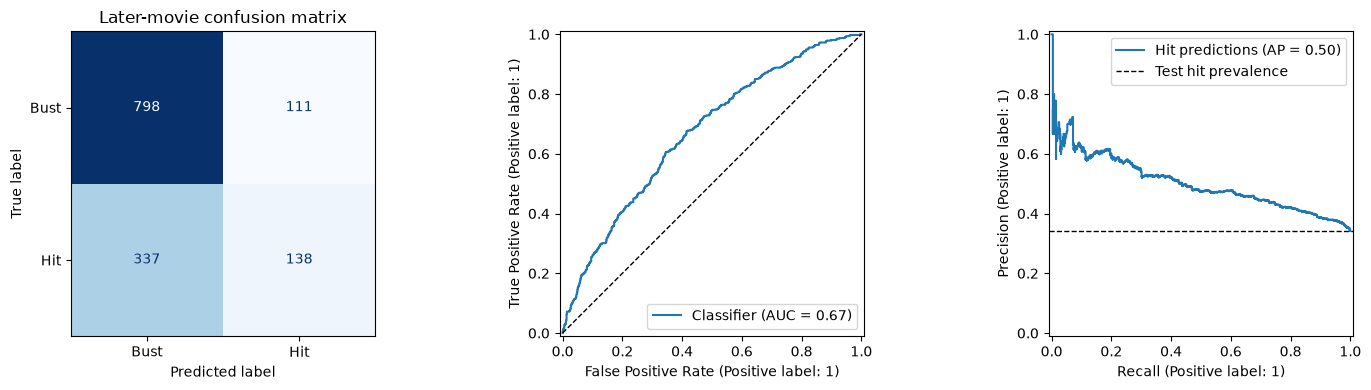

In [9]:
prediction_examples = movies.loc[test_mask, ["title_tmdb", "release_date", "success"]].copy()
prediction_examples["hit_probability"] = test_probability
prediction_examples["predicted_success"] = test_prediction
prediction_examples["correct"] = prediction_examples["success"].eq(test_prediction)
display(prediction_examples.head(10).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=[0, 1], display_labels=["Bust", "Hit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Later-movie confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name="Classifier")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[2], name="Hit predictions")
axes[2].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label="Test hit prevalence")
axes[2].legend()
plt.tight_layout()
plt.show()

## 7. Compare feature groups within training
Use three expanding chronological validation splits, identical across models and feature versions. Fresh preprocessing is fitted for every fold. Training dates precede validation dates in each split. Compare mean validation ROC AUC, macro F1, and balanced accuracy; no feature version is selected using the later test data.

The comparisons are cumulative: movie characteristics, plus director history, plus actor history, then company/franchise history. They do not isolate individual transformations or prove causation.

This section retains the original estimator settings to isolate the cumulative feature comparison. It does not retune each feature version. The tuning section above searches settings using all features; its selection score is not an independent estimate after selection.

In [10]:
movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

In [11]:
# Split unique dates so equal release dates never appear on both sides.
training_dates = movies.loc[train_mask, "release_date"]
unique_dates = np.sort(training_dates.unique())
validation_splits = []
split_details = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_dates), 1):
    fit_indices = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_indices = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_indices, "release_date"].max() < movies.loc[validation_indices, "release_date"].min()
    assert set(fit_indices).isdisjoint(validation_indices)
    assert set(fit_indices).union(validation_indices).issubset(set(X_train.index))
    validation_splits.append((fold, fit_indices, validation_indices))
    split_details.append({
        "Fold": fold, "Training movies": len(fit_indices), "Validation movies": len(validation_indices),
        "Training ends": movies.loc[fit_indices, "release_date"].max().date(),
        "Validation starts": movies.loc[validation_indices, "release_date"].min().date(),
        "Validation ends": movies.loc[validation_indices, "release_date"].max().date(),
    })
display(pd.DataFrame(split_details))

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,1329,1427,1999-12-03,1999-12-10,2006-11-01
1,2,2756,1384,2006-11-01,2006-11-02,2012-03-12
2,3,4140,1395,2012-03-12,2012-03-14,2017-11-17


In [12]:
comparison_rows = []
for version, columns in feature_versions.items():
    for fold, fit_indices, validation_indices in validation_splits:
        assert y_train.loc[fit_indices].nunique() == 2
        assert y_train.loc[validation_indices].nunique() == 2
        candidate = make_classifier(columns)
        candidate.fit(X_train.loc[fit_indices, columns], y_train.loc[fit_indices])
        probability = candidate.predict_proba(X_train.loc[validation_indices, columns])[:, list(candidate.classes_).index(1)]
        predicted = (probability >= BASE_THRESHOLD).astype(int)
        metrics = classification_scores(version, "Validation", y_train.loc[validation_indices], predicted, probability)
        comparison_rows.append({"Version": version, "Fold": fold, "Predictors": len(columns), **{key: value for key, value in metrics.items() if key not in ["Model", "Split"]}})
feature_fold_results = pd.DataFrame(comparison_rows)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"),
    Validation_AUC=("ROC AUC", "mean"), AUC_std=("ROC AUC", "std"),
    Validation_macro_F1=("Macro F1", "mean"),
    Validation_hit_F1=("Hit F1", "mean"),
    Validation_hit_precision=("Hit precision", "mean"),
    Validation_hit_recall=("Hit recall", "mean"),
    Validation_balanced_accuracy=("Balanced accuracy", "mean"),
    Validation_accuracy=("Accuracy", "mean"),
)
display(feature_comparison.round(4))
display(feature_fold_results.pivot(index="Version", columns="Fold", values="ROC AUC").reindex(feature_versions).round(4))
assert len(feature_fold_results) == len(feature_versions) * N_VALIDATION_SPLITS

,Predictors,Validation_AUC,AUC_std,Validation_macro_F1,Validation_hit_F1,Validation_hit_precision,Validation_hit_recall,Validation_balanced_accuracy,Validation_accuracy
Version,,,,,,,,,
Movie characteristics,27,0.6530,0.0458,0.5616,0.3543,0.6185,0.2519,0.5790,0.6618
+ Director history,36,0.6585,0.0440,0.5635,0.3575,0.6194,0.2538,0.5803,0.6627
+ Actor history,38,0.6593,0.0434,0.5634,0.3586,0.6137,0.2547,0.5794,0.6608
All features,40,0.6581,0.0453,0.5654,0.3621,0.6169,0.2573,0.5809,0.6618


Fold,1,2,3
Version,,,
Movie characteristics,0.6017,0.6672,0.6900
+ Director history,0.6103,0.6687,0.6966
+ Actor history,0.6135,0.6645,0.6998
All features,0.6093,0.6664,0.6987


## Interpretation and limits
Financial histories use only earlier years and update through time, representing rolling predictions rather than a single forecast at the split date. Retrospective sources do not prove when earlier movies' final outcomes became known. The cohort excludes missing financial values and applies cleaning floors; results do not represent all movies.

Section 4 selects estimator settings using training-period validation. Section 4b additionally selects a threshold using training-period validation; original and settings-only results retain the 0.5 threshold. Compare financial classifiers with one another using the same metrics and splits, not with rating-model MAE/R². Do not repeatedly tune using the already-inspected test period.

The current selection goal is hit F1 subject to a mean validation precision guard. Report hit precision, recall, and F1 together; do not describe F1 itself as giving precision extra weight. Test outcomes never set the precision requirement.

## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [13]:
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("gradient_boosting.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/success/gradient_boosting.json
